In [2]:
import torch
import random
import numpy as np
import matplotlib.pyplot as plt

from datasets import load_dataset
from sklearn.model_selection import train_test_split

In [3]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print(device)

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

cuda
NVIDIA GeForce RTX 4090


In [4]:
dataset = load_dataset(
            "simonMadec/VegAnn"
)

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'],
        num_rows: 3775
    })
})


In [5]:
sample = dataset['train'][0]

print(sample.keys())

dict_keys(['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'])


In [6]:
import random

templates = [

"An agricultural image showing {} plants.",

"A field image containing {} crops.",

"An aerial agricultural image of {} plants.",

"An image of a cultivated field with {} vegetation.",

"A crop field populated by {} plants.",

"An agricultural scene showing {} growing in the field."

]

In [7]:
orientation_mapping = {

"Nadir":"nadir",

"45":"45-degree",

"DHP":"hemispherical",

"Na":""

}


system_mapping = {

"UAV":"drone",

"Phone Camera":"phone camera",

"Handeld Cameras":"handheld camera",

"Phenomobile":"phenomobile",

"IOT":"iot sensor",

"DHP":"hemispherical camera",

"Na":""

}

In [8]:
def make_caption(sample):

    species = sample['Species']

    orientation = orientation_mapping.get(
                        sample['Orientation'],
                        ''
                    )

    system = system_mapping.get(
                    sample['System'],
                    ''
                )

    caption = random.choice(templates).format(species)

    extras = []

    if orientation:
        extras.append(
            f"captured from a {orientation} view"
        )

    if system:
        extras.append(
            f"using a {system}"
        )

    if extras:
        caption += " " + ", ".join(extras) + "."

    return caption

In [9]:
for i in range(10):

    sample = dataset['train'][i]

    print(make_caption(sample))

A crop field populated by Mix plants. captured from a nadir view, using a handheld camera.
An agricultural scene showing Mix growing in the field. captured from a nadir view, using a handheld camera.
An aerial agricultural image of Mix plants. captured from a nadir view, using a handheld camera.
An aerial agricultural image of Mix plants. captured from a nadir view, using a handheld camera.
A field image containing Mix crops. captured from a nadir view, using a handheld camera.
An aerial agricultural image of Mix plants. captured from a nadir view, using a handheld camera.
A crop field populated by Mix plants. captured from a nadir view, using a handheld camera.
A field image containing Mix crops. captured from a nadir view, using a handheld camera.
A crop field populated by Mix plants. captured from a nadir view, using a handheld camera.
An agricultural scene showing Mix growing in the field. captured from a nadir view, using a handheld camera.


In [10]:
captioned_dataset = []


for sample in dataset['train']:


    caption = make_caption(sample)


    image = sample['image']


    captioned_dataset.append(

        {

        'image':image,

        'caption':caption

        }

    )


print(

len(captioned_dataset)

)

3775


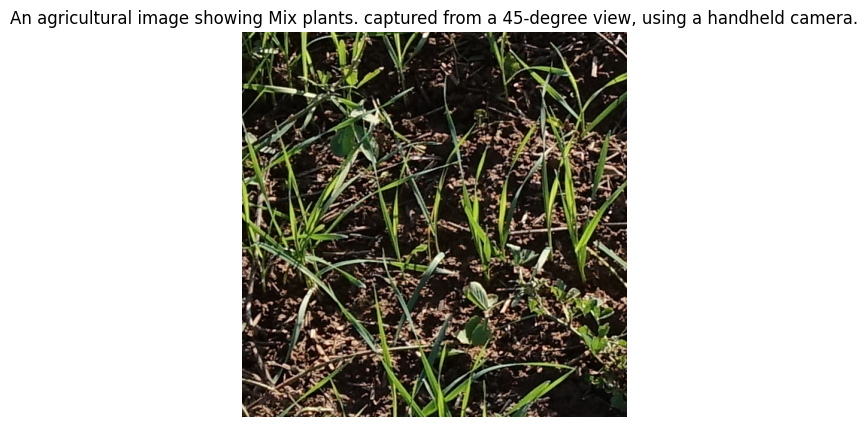

In [11]:
idx = 50



sample = captioned_dataset[idx]



plt.figure(figsize=(5,5))

plt.imshow(

sample['image']

)


plt.title(

sample['caption']

)


plt.axis('off')

plt.show()

In [12]:
train_data , val_data = train_test_split(


                    captioned_dataset,


                    test_size=0.2,


                    random_state=42

)



print(len(train_data))
print(len(val_data))

3020
755


In [13]:
sample = dataset['train'][0]

for k,v in sample.items():

    if k not in ['image','mask']:

        print(k)
        print(v)
        print()

System
Handeld Cameras

Orientation
Nadir

latitude
43.916686

longitude
4.879169

date
2019-06

LocAcc
1

Species
Mix

Owner
Arvalis

Dataset-Name
Literal

TVT-split1
Test

TVT-split2
Training

TVT-split3
Training

TVT-split4
Training

TVT-split5
Training



In [14]:
species = set()
orientation = set()
system = set()

for s in dataset['train']:

    species.add(s['Species'])

    orientation.add(s['Orientation'])

    system.add(s['System'])


print("Species")
print(species)

print("\nOrientation")
print(orientation)

print("\nSystem")
print(system)

Species
{'Tabacco', 'Barley', 'Maize', 'Sorrel', 'Faba beans', 'Cabbage', 'Raspberry', 'Radish', 'Vetch', 'Mustard', 'Alfalfa', 'Pea', 'Sunflower', 'Mix', 'Rapeseed', 'Potato', 'Wheat', 'Sugarbeet', 'Sorghum', 'Soybean', 'Rice', 'Bean', 'Na', 'Grassland', 'Pepper', 'Oat', 'Onion'}

Orientation
{'45', 'DHP', 'Na', 'Nadir'}

System
{'Handeld Cameras', 'DHP', 'Na', 'Phenomobile', 'Phone Camera', 'UAV', 'IOT'}


In [15]:
#IMPORTING AGRICLIP MODULES
import sys

sys.path.append(
"/home/zahranadeem/AgriCLIP/AgriCLIP_alignment"
)

sys.path.append(
"/home/zahranadeem/AgriCLIP"
)

In [16]:
from TextToConcept import TextToConcept
from LinearAligner import LinearAligner

In [17]:
import torch


model = torch.hub.load(
    'facebookresearch/dino:main',
    'dino_resnet50',
    pretrained=True
)

Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


In [18]:
model.load_state_dict(

torch.load(

"/home/zahranadeem/AgriCLIP/Weights/dino_pretrain.pth",

map_location='cpu'

)

)

model.eval()


print("DINO loaded")

DINO loaded


In [19]:
model.cuda()


def forward_features(x):

    return model(x)



model.forward_features = forward_features

In [20]:
from torchvision import transforms


IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.ToTensor(),

    transforms.Normalize(

        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )

])

In [21]:
sample = train_data[0]

img = sample['image']


img = transform(img)

img = img.unsqueeze(0)

img = img.cuda()



with torch.no_grad():

    feat = model.forward_features(img)


print(feat.shape)

torch.Size([1, 2048])


In [22]:
text_to_concept = TextToConcept(

model,

'Dino'

)

print("loaded")

loaded


In [23]:
text_to_concept.load_linear_aligner(

"/home/zahranadeem/AgriCLIP/Weights/Aligned_Models/Agri_Dino_aligner_DDEF_CDEF.pth"

)

print("aligner loaded")

aligner loaded


In [24]:
#FINE TUNING ALIGNER Frozen DINO and CLIP text encoder 

from torch.utils.data import Dataset


class VegAnnCaptionDataset(Dataset):

    def __init__(self,data):

        self.data=data


    def __len__(self):
        return len(self.data)


    def __getitem__(self,idx):

        sample=self.data[idx]


        image = transform(

                    sample['image']

                )


        caption = sample['caption']


        return image,caption

In [25]:
from torch.utils.data import DataLoader


train_loader = DataLoader(

                    train_data,

                    batch_size=32,

                    shuffle=True,

                    num_workers=4

)


val_loader = DataLoader(

                    val_data,

                    batch_size=32

)

In [26]:
print(len(train_data))
print(train_data[0].keys())

3020
dict_keys(['image', 'caption'])


In [27]:
#extracting DINO feaures
dino_features = []
captions = []

N = 500

for i in range(N):

    sample = train_data[i]

    image = transform(
        sample['image']
    )

    image = image.unsqueeze(0).cuda()


    with torch.no_grad():

        feat = model.forward_features(
            image
        )



    dino_features.append(

        feat.squeeze().cpu().numpy()

    )


    captions.append(

        sample['caption']

    )


print(len(dino_features))

500


In [28]:
#Extracting CLIP features 
clip_features = []



for caption in captions:


    vec = text_to_concept.encode_text(

        [[caption]]

    )


    clip_features.append(

        vec.squeeze().cpu().numpy()

    )



print(len(clip_features))


500


In [29]:
import numpy as np


dino_features = np.stack(
                    dino_features
                )


clip_features = np.stack(
                    clip_features
                )



print(dino_features.shape)
print(clip_features.shape)

(500, 2048)
(500, 512)


In [30]:
#Train a new aligner
from LinearAligner import LinearAligner


new_aligner = LinearAligner()


new_aligner.train(

    dino_features,

    clip_features,

    epochs=6

)

Training linear aligner ...
Linear alignment: ((500, 2048)) --> ((500, 512)).
Initial MSE, R^2: 6.243, -0.387
Epoch number, loss: 0, 3.703
Epoch number, loss: 1, 3.007
Epoch number, loss: 2, 2.021
Epoch number, loss: 3, 1.503
Epoch number, loss: 4, 1.380
Epoch number, loss: 5, 1.244
Final MSE, R^2 = 1.024, 0.772


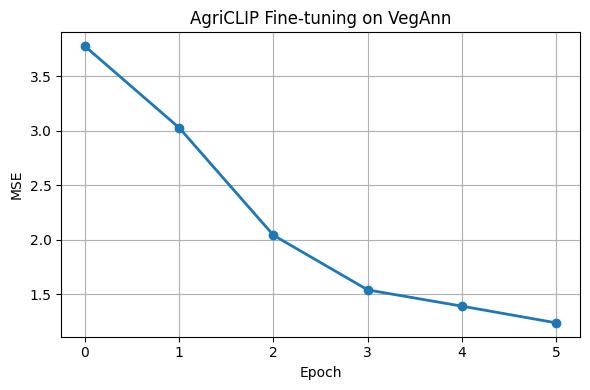

In [31]:
import matplotlib.pyplot as plt

epochs = [0,1,2,3,4,5]
mse = [3.775,3.027,2.042,1.541,1.392,1.239]

plt.figure(figsize=(6,4))

plt.plot(epochs,
         mse,
         marker='o',
         linewidth=2)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("AgriCLIP Fine-tuning on VegAnn")

plt.grid(True)

plt.tight_layout()

plt.savefig("training_loss.png",
            dpi=300)

plt.show()

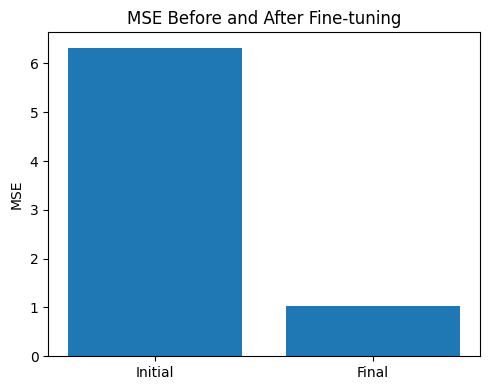

In [32]:
import matplotlib.pyplot as plt


labels=['Initial','Final']
values=[6.322,1.022]


plt.figure(figsize=(5,4))

plt.bar(labels,
        values)


plt.ylabel("MSE")


plt.title("MSE Before and After Fine-tuning")


plt.tight_layout()

plt.savefig(
            "mse_comparison.png",
            dpi=300
            )

plt.show()

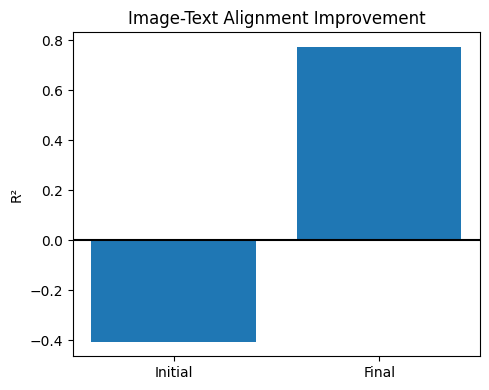

In [33]:
import matplotlib.pyplot as plt


labels=['Initial','Final']
r2=[-0.405,0.773]


plt.figure(figsize=(5,4))

plt.bar(labels,
        r2)


plt.axhline(0,
            color='black')


plt.ylabel("R²")


plt.title("Image-Text Alignment Improvement")


plt.tight_layout()


plt.savefig(

"r2_improvement.png",

dpi=300

)

plt.show()

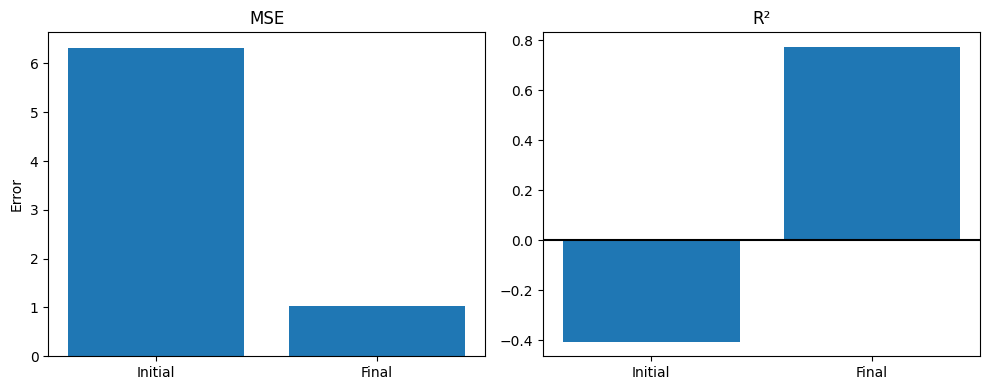

In [34]:
import matplotlib.pyplot as plt


fig,ax=plt.subplots(1,2,figsize=(10,4))


########################

mse=[6.322,1.022]

ax[0].bar(

['Initial','Final'],
mse

)

ax[0].set_title("MSE")
ax[0].set_ylabel("Error")


########################


r2=[-0.405,0.773]


ax[1].bar(

['Initial','Final'],
r2

)


ax[1].axhline(

0,

color='black'

)

ax[1].set_title("R²")



plt.tight_layout()

plt.savefig(

"agriclip_results.png",

dpi=300

)


plt.show()

In [35]:
text_to_concept.linear_aligner = new_aligner

In [37]:
species_list = sorted(list(set(dataset["train"]["Species"])))

print("Number of species:", len(species_list))
print(species_list)

Number of species: 27
['Alfalfa', 'Barley', 'Bean', 'Cabbage', 'Faba beans', 'Grassland', 'Maize', 'Mix', 'Mustard', 'Na', 'Oat', 'Onion', 'Pea', 'Pepper', 'Potato', 'Radish', 'Rapeseed', 'Raspberry', 'Rice', 'Sorghum', 'Sorrel', 'Soybean', 'Sugarbeet', 'Sunflower', 'Tabacco', 'Vetch', 'Wheat']


In [38]:
species_classifier = text_to_concept.get_zero_shot_classifier(

    species_list,

    prompts=[
        "An agricultural image showing {} plants."
    ]

)

In [39]:
import random
import numpy as np

correct_top1 = 0
correct_top5 = 0

indices = random.sample(
            range(len(dataset["train"])),
            100
          )

for idx in indices:

    sample = dataset["train"][idx]

    image = sample["image"]
    gt = sample["Species"]

    img_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = species_classifier(img_tensor)

    scores = logits.squeeze().cpu().numpy()

    top5 = np.argsort(scores)[-5:][::-1]

    pred1 = species_list[top5[0]]

    if pred1 == gt:
        correct_top1 += 1

    if gt in [species_list[i] for i in top5]:
        correct_top5 += 1


print("Top1 Accuracy:",
      correct_top1/100)

print("Top5 Accuracy:",
      correct_top5/100)

Top1 Accuracy: 0.7
Top5 Accuracy: 0.83


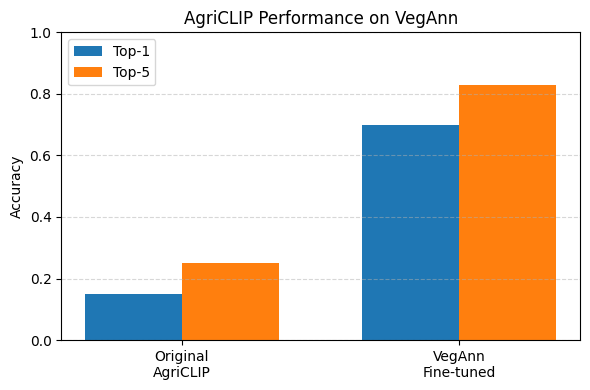

In [40]:
import matplotlib.pyplot as plt
import numpy as np

# Models
models = ['Original\nAgriCLIP', 'VegAnn\nFine-tuned']

# Accuracies
top1 = [0.15, 0.70]
top5 = [0.25, 0.83]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(6,4))

plt.bar(x-width/2, top1, width, label='Top-1')
plt.bar(x+width/2, top5, width, label='Top-5')

plt.xticks(x, models)
plt.ylabel('Accuracy')
plt.ylim(0,1)

plt.title('AgriCLIP Performance on VegAnn')

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()

plt.savefig(
    'vegann_top1_top5.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

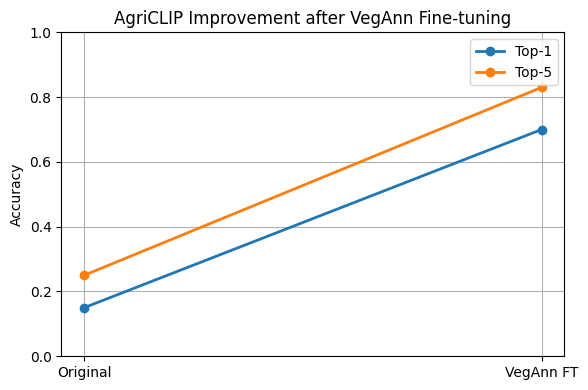

In [41]:
import matplotlib.pyplot as plt

models = ['Original', 'VegAnn FT']

top1 = [0.15,0.70]
top5 = [0.25,0.83]

fig, ax = plt.subplots(figsize=(6,4))

ax.plot(models,
        top1,
        marker='o',
        linewidth=2,
        label='Top-1')

ax.plot(models,
        top5,
        marker='o',
        linewidth=2,
        label='Top-5')

ax.set_ylim(0,1)

ax.set_ylabel("Accuracy")

ax.set_title("AgriCLIP Improvement after VegAnn Fine-tuning")

ax.grid(True)

ax.legend()

plt.tight_layout()

plt.savefig(
    "vegann_accuracy_curve.png",
    dpi=300
)

plt.show()

In [43]:
text_to_concept.save_linear_aligner(
    "vegann_aligner.pth"
)